# Real-Time IDS — ML Model Development (Team Member 1)
### Local / VS Code version

**Project:** Real-Time Intrusion Detection System (0th Review)
**Dataset:** CIC-IDS2017 (flow-level features)
**Owner:** Member 1 — Machine Learning & Model Development

Same pipeline as the Colab version, adapted to run locally in VS Code (Jupyter extension) — no Drive mounting, local file paths, and a memory-saving option since you're not fighting Colab's 12.7GB RAM ceiling anymore (your own machine's RAM is the new limit, so check that below too).

**One-time setup before running this notebook:**
1. Install the Jupyter extension in VS Code (if not already)
2. Create a virtual environment and install packages — see the `requirements.txt` provided alongside this notebook, or run in a terminal:
   ```
   python -m venv venv
   venv\Scripts\activate        # Windows
   source venv/bin/activate     # macOS/Linux
   pip install -r requirements.txt
   ```
3. Select that `venv` as your notebook's kernel in VS Code (top-right kernel picker)
4. Place the extracted CIC-IDS2017 CSVs in a local folder and update `DATASET_DIR` below

## 1. Imports & config

Edit `DATASET_DIR` and `OUTPUT_DIR` to match folders on your own computer — no `/content/drive/...` prefix needed anymore.

In [4]:
import os
import glob
import numpy as np
import pandas as pd
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, f1_score, precision_score,
    confusion_matrix, classification_report
)
from xgboost import XGBClassifier


DATASET_DIR = r'C:\project work\CCNS project\CIC-IDS-2017'
OUTPUT_DIR  = './model_artifacts/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42

## 2. Check available RAM before loading (quick sanity check)

Since RAM is now your own machine's limit instead of Colab's, this prints what you're working with so you can judge whether to use the full dataset or the memory-saving sample option later.

In [5]:
import psutil

mem = psutil.virtual_memory()
print(f"Total RAM: {mem.total / 1e9:.1f} GB")
print(f"Available RAM: {mem.available / 1e9:.1f} GB")

if mem.available / 1e9 < 6:
    print("\n⚠️  Less than 6GB free — strongly consider using the SAMPLE_FRACTION option in the loading cell below.")
else:
    print("\nLooks fine for the full dataset, but keep an eye on RAM during training (Task Manager / Activity Monitor).")

Total RAM: 25.4 GB
Available RAM: 12.1 GB

Looks fine for the full dataset, but keep an eye on RAM during training (Task Manager / Activity Monitor).


## 3. Load the dataset

Loads all CSVs from `DATASET_DIR`. Set `SAMPLE_FRACTION` below 1.0 to load only a fraction of each file if your machine is memory-constrained — much simpler than loading everything then downsampling after.

In [6]:
# Set this below 1.0 (e.g. 0.3) if your machine has limited RAM.
SAMPLE_FRACTION = 1.0

csv_files = glob.glob(os.path.join(DATASET_DIR, '*.csv'))
print(f"Found {len(csv_files)} CSV files:")
for f in csv_files:
    print(' -', os.path.basename(f))

df_list = []
for f in csv_files:
    temp = pd.read_csv(f, low_memory=False)
    temp.columns = temp.columns.str.strip()  # CIC-IDS2017 columns have leading spaces
    if SAMPLE_FRACTION < 1.0:
        temp = temp.sample(frac=SAMPLE_FRACTION, random_state=42)
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)
print("\nCombined shape:", df.shape)
df.head()

Found 8 CSV files:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv

Combined shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## 4. Memory optimization (optional but recommended)

Downcasts numeric columns to smaller dtypes (float64→float32, int64→int32 where safe). Typically cuts memory usage by ~40-50% with no accuracy impact — worth running if your machine is tight on RAM.

In [7]:
def reduce_memory(df):
    start_mem = df.memory_usage(deep=True).sum() / 1e6
    for col in df.select_dtypes(include=['float64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='float')
    for col in df.select_dtypes(include=['int64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')
    end_mem = df.memory_usage(deep=True).sum() / 1e6
    print(f"Memory usage: {start_mem:.1f} MB -> {end_mem:.1f} MB ({100*(start_mem-end_mem)/start_mem:.0f}% reduction)")
    return df

df = reduce_memory(df)

Memory usage: 1922.9 MB -> 1039.8 MB (46% reduction)


## 5. Initial exploration

Check class distribution (this drives the imbalance-handling decision later), nulls, and dtypes.

In [8]:
print("Label column value counts:\n")
print(df['Label'].value_counts())

print("\nMissing values per column (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nInfinite values present:", np.isinf(df.select_dtypes(include=[np.number])).sum().sum())

Label column value counts:

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Missing values per column (top 10):
Flow Bytes/s                   1358
Flow Duration                     0
Destination Port                  0
Total Backward Packets            0
Total Length of Fwd Packets       0
Total Length of Bwd Packets       0
Total Fwd Packets                 0
Fwd Packet Length Max             0
Fwd Packet Length Min             0
Fwd Packe

## 6. Data cleaning

- Drop duplicate rows
- Replace infinite values with NaN, then drop
- Drop identifier/non-generalizable columns
- Drop constant (zero-variance) columns

In [9]:
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before - len(df)} duplicate rows")

df = df.replace([np.inf, -np.inf], np.nan)
before = len(df)
df = df.dropna()
print(f"Dropped {before - len(df)} rows with NaN/inf")

# NOTE: keep this list in sync with what Member 2 can actually compute live —
# anything dropped here should NOT be expected from the real-time extractor either.
drop_cols = [c for c in ['Flow ID', 'Source IP', 'Src IP', 'Destination IP', 'Dst IP',
                          'Timestamp', 'SimillarHTTP', 'Fwd Header Length.1'] if c in df.columns]
df = df.drop(columns=drop_cols)
print("Dropped identifier/non-generalizable columns:", drop_cols)

nunique = df.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
df = df.drop(columns=constant_cols)
print("Dropped constant columns:", constant_cols)

print("\nShape after cleaning:", df.shape)

Dropped 308387 duplicate rows
Dropped 1564 rows with NaN/inf
Dropped identifier/non-generalizable columns: ['Fwd Header Length.1']
Dropped constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Shape after cleaning: (2520792, 70)


## 7. Feature selection

Start with all remaining numeric flow-level features. Optionally drop highly correlated pairs (|correlation| > 0.95) — safe to skip on first pass and revisit after baseline results.

In [10]:
feature_cols = [c for c in df.columns if c != 'Label']
X_full = df[feature_cols]

# Optional: correlation-based pruning (uncomment to apply)
# corr_matrix = X_full.corr().abs()
# upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
# feature_cols = [c for c in feature_cols if c not in to_drop]
# print(f"Dropped {len(to_drop)} highly correlated features")

print(f"Final feature count: {len(feature_cols)}")
print(feature_cols)

Final feature count: 69
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Down/U

## 8. Label encoding

Multiclass: Normal → 0, each attack type → its own class.

**Save `label_encoder.pkl` — Member 3's dashboard needs this mapping to display attack names, not raw class numbers.**

In [11]:
le = LabelEncoder()
y = le.fit_transform(df['Label'])

label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Label mapping:")
for label, code_val in label_mapping.items():
    print(f"  {label} -> {code_val}")

X = df[feature_cols].values

Label mapping:
  BENIGN -> 0
  Bot -> 1
  DDoS -> 2
  DoS GoldenEye -> 3
  DoS Hulk -> 4
  DoS Slowhttptest -> 5
  DoS slowloris -> 6
  FTP-Patator -> 7
  Heartbleed -> 8
  Infiltration -> 9
  PortScan -> 10
  SSH-Patator -> 11
  Web Attack � Brute Force -> 12
  Web Attack � Sql Injection -> 13
  Web Attack � XSS -> 14


## 9. Train/test split

Stratified split to preserve class ratios.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

# Free the full arrays now that train/test are split, to save RAM
del X, X_full

Train shape: (2016633, 69)  Test shape: (504159, 69)


## 10. Feature scaling

Fit on train only, apply to both splits. Save the scaler — Member 2's live pipeline must scale incoming flow features identically before they reach the model.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

del X_train, X_test  # free raw (unscaled) copies

## 11. Class imbalance check

Class weighting is applied directly inside each model (`class_weight='balanced'`). If minority-class recall is still poor after the baseline, switch to SMOTE (commented out below — note it increases RAM usage since it generates synthetic samples, be mindful on a memory-constrained machine).

In [14]:
# Optional SMOTE — try this if class_weight alone isn't enough for rare classes
# from imblearn.over_sampling import SMOTE
# smote = SMOTE(random_state=RANDOM_STATE)
# X_train_scaled, y_train = smote.fit_resample(X_train_scaled, y_train)
# print("After SMOTE:", X_train_scaled.shape)

print("Class distribution in training set:")
print(pd.Series(y_train).value_counts())

Class distribution in training set:
0     1676040
4      138277
2      102411
10      72555
3        8229
7        4745
6        4308
5        4182
11       2575
1        1558
12       1176
14        522
9          29
13         17
8           9
Name: count, dtype: int64


## 12. Train & compare models

Random Forest (baseline), XGBoost, and MLP. `n_jobs=-1` uses all CPU cores — on a local machine this is usually a lot faster than Colab's free-tier CPU, but also uses more of your own RAM during training. If you hit memory pressure, drop `n_jobs=-1` to `n_jobs=2` (fewer parallel workers = less peak memory, slower training) as a trade-off.

In [15]:
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, eval_metric='mlogloss',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'MLP': MLPClassifier(
        hidden_layer_sizes=(128, 64), max_iter=300, random_state=RANDOM_STATE
    ),
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
print("Done.")

Training Random Forest...
Training XGBoost...
Training MLP...
Done.


## 13. Evaluation

Per the deck's KPI hierarchy: **Macro Recall (primary)** → **Macro F1 (secondary)** → **Accuracy (supporting)** → **Confusion Matrix (diagnostic)**.

In [16]:
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values('Macro Recall', ascending=False)
print(results_df.to_string(index=False))

        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
Random Forest  0.997814         0.895806      0.860008  0.849936
      XGBoost  0.997826         0.738372      0.771020  0.744299
          MLP  0.997195         0.810648      0.707143  0.711478


In [17]:
# Detailed report + confusion matrix for the best model by Macro Recall
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"Best model (by Macro Recall): {best_model_name}\n")
print(classification_report(y_test, y_pred_best, target_names=le.classes_, zero_division=0))

cm = confusion_matrix(y_test, y_pred_best)
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)
cm_df

Best model (by Macro Recall): Random Forest

                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    419011
                       Bot       0.44      0.99      0.61       390
                      DDoS       1.00      1.00      1.00     25603
             DoS GoldenEye       0.99      1.00      0.99      2057
                  DoS Hulk       0.99      1.00      1.00     34569
          DoS Slowhttptest       0.99      1.00      0.99      1046
             DoS slowloris       0.99      0.99      0.99      1077
               FTP-Patator       1.00      1.00      1.00      1186
                Heartbleed       1.00      0.50      0.67         2
              Infiltration       0.88      1.00      0.93         7
                  PortScan       0.99      1.00      0.99     18139
               SSH-Patator       1.00      1.00      1.00       644
  Web Attack � Brute Force       0.75      0.72      0.74       294
We

,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
BENIGN,418116,490,6,11,182,6,4,0,0,1,189,1,2,0,3
Bot,4,386,0,0,0,0,0,0,0,0,0,0,0,0,0
DDoS,0,0,25602,0,1,0,0,0,0,0,0,0,0,0,0
DoS GoldenEye,3,0,0,2048,6,0,0,0,0,0,0,0,0,0,0
DoS Hulk,6,0,0,5,34556,0,0,0,0,0,2,0,0,0,0
DoS Slowhttptest,0,0,0,0,0,1042,4,0,0,0,0,0,0,0,0
DoS slowloris,5,0,0,0,0,4,1066,0,0,0,1,0,1,0,0
FTP-Patator,0,0,0,0,0,0,0,1185,0,0,0,0,0,0,1
Heartbleed,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
Infiltration,0,0,0,0,0,0,0,0,0,7,0,0,0,0,0


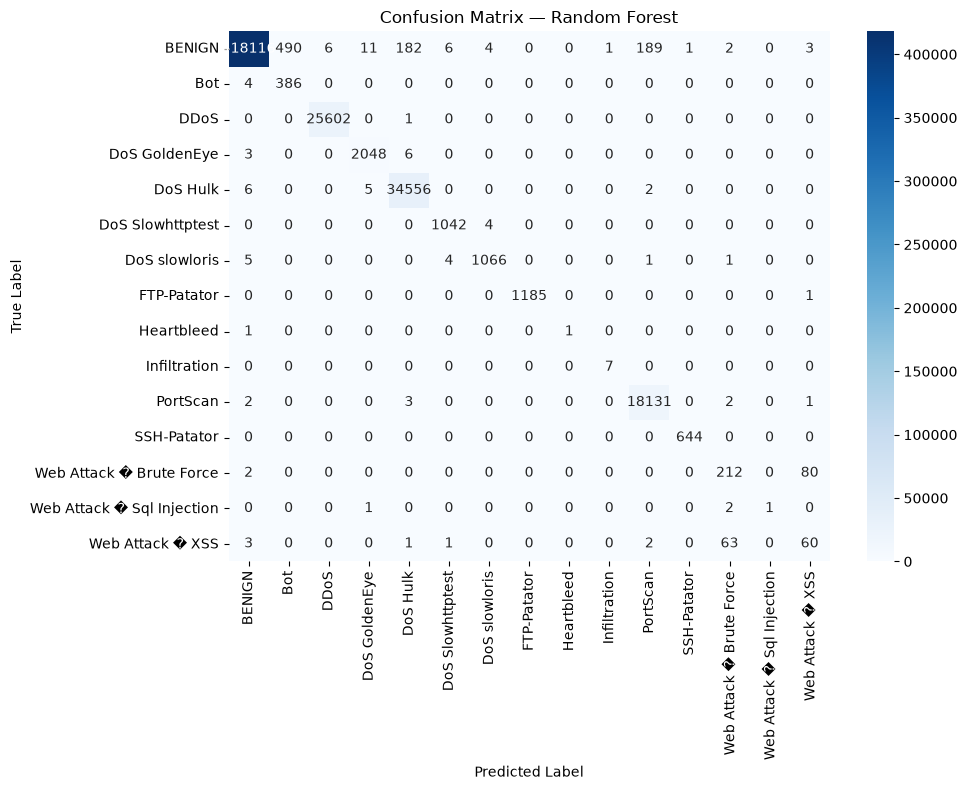

In [18]:
# Visualize confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix — {best_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

## 14. Save the final model + preprocessing pipeline

Saved locally to `OUTPUT_DIR`. These four artifacts are the hand-off to Member 2 (real-time feature extraction) and Member 3 (backend/dashboard) — zip this folder and share it with them (e.g. via your shared Drive, WhatsApp, or a shared repo).

| File | Used by | Purpose |
|---|---|---|
| `best_model.pkl` | Member 2's pipeline | Final trained classifier |
| `scaler.pkl` | Member 2's pipeline | Must scale live flow features identically to training |
| `label_encoder.pkl` | Member 3's dashboard | Maps predicted class number → attack name |
| `feature_columns.pkl` | Member 2's pipeline | Exact feature order/names the model expects |

**Critical for Member 2:** the live feature extractor must produce features in the *same order and names* as `feature_columns.pkl`, then apply `scaler.pkl` before calling `best_model.pkl.predict()`.

In [19]:
joblib.dump(best_model, os.path.join(OUTPUT_DIR, 'best_model.pkl'))
joblib.dump(scaler, os.path.join(OUTPUT_DIR, 'scaler.pkl'))
joblib.dump(le, os.path.join(OUTPUT_DIR, 'label_encoder.pkl'))
joblib.dump(feature_cols, os.path.join(OUTPUT_DIR, 'feature_columns.pkl'))

print(f"Saved artifacts to: {os.path.abspath(OUTPUT_DIR)}")
print(" - best_model.pkl       (", best_model_name, ")")
print(" - scaler.pkl")
print(" - label_encoder.pkl")
print(" - feature_columns.pkl  (", len(feature_cols), "features )")

Saved artifacts to: c:\project work\CCNS project\model_artifacts
 - best_model.pkl       ( Random Forest )
 - scaler.pkl
 - label_encoder.pkl
 - feature_columns.pkl  ( 69 features )


## 15. Next steps

- [ ] Confirm `DATASET_DIR` points to your local CIC-IDS2017 CSV folder
- [ ] If RAM is tight, set `SAMPLE_FRACTION` (Section 3) below 1.0 or lower `n_jobs` (Section 12)
- [ ] Re-run with SMOTE (Section 11) if minority-class Macro Recall is still weak
- [ ] Try correlation-based feature pruning (Section 7) and compare Macro F1
- [ ] Evaluate SNN as an experimental 4th model per the deck (Slide 7) if time allows
- [ ] Zip `model_artifacts/` and share with Member 2 (needs `scaler.pkl` + `feature_columns.pkl` + `best_model.pkl`) and Member 3 (needs `label_encoder.pkl`)